# Assignment 02 — Reproduction of *LogADReft* (Lim, Zhu & Pang, PAKDD 2025)
**Course:** Deep Learning (AIC 401) · **Students:** Muhammad Abdullah Abrar (01-134232-223), Shehryar Zafar (01-134232-236)

**Paper:** *Adapting Large Language Models for Parameter-Efficient Log Anomaly Detection* — DOI 10.1007/978-981-96-8298-0_26 · arXiv:2503.08045  
**Authors' code (cloned, not copied):** https://github.com/mala-lab/LogADReft  
**Dataset:** Le & Zhang (ICSE 2022) preprocessed log datasets, Zenodo record 8115559

### How to run
1. Run this notebook on Google Colab (v2: every cell reloads its settings and skips finished work, so it survives session restarts). *Runtime → Change runtime type → GPU (T4 is enough)*. Run the cells top to bottom.
2. Run the cells top to bottom. Edit only the CONFIG block in the first code cell if needed (sample sizes). Defaults need roughly 1-2 h on a free T4 (our estimate, not measured).

### Scope of this reproduction (what is and is not reproduced)
* **Reproduced:** RoBERTa-ReFT and GPT2-ReFT on **HDFS** and **BGL** (the small models we can afford; ReFT is the base for Assignment 03).
* **Not reproduced:** Llama-3 runs (8B parameters), LoRA runs, Spirit/Thunderbird, and the extra experiments (rank sweep, train-ratio, unstable logs, cross-dataset).
* **Deviation 1 — subsampling:** the authors' code supports `--max_n_train_example/--max_n_eval_example`; we use it because the full splits take far too long on a free GPU. This changes the class ratio of the test set (their sampler keeps at most 10% anomalies), so our numbers are **not** an exact reproduction of the paper's full-test-set numbers.
* **Deviation 2 — hardware:** on GPUs without bf16 support (e.g. T4) we use float32 and an effective batch of 32 via 16 x 2 gradient accumulation.
* Every reproduced number below is produced by this notebook. The only typed-in numbers are the original paper's reported values (variable `PAPER`).

In [ ]:
# ===== CELL 1: setup + CONFIG. Run this first (about 1-2 min). If Colab asks to "restart session", restart, then run this cell again. =====
import os, sys, json, subprocess
def sh(c): subprocess.run(c, shell=True, check=True)
os.chdir("/content")
if not os.path.isdir("LogADReft"): sh("git clone -q https://github.com/mala-lab/LogADReft.git")
os.chdir("/content/LogADReft")
# authors' pins + packages their code needs but does not list. pyvene must be 0.1.6 (newer versions break the authors' main.py)
sh(f'{sys.executable} -m pip install -q -r requirements.txt wandb scikit-learn pandas matplotlib requests "pyvene==0.1.6"')

# ---- CONFIG (edit here) ----
CONFIG = dict(
    DATASETS = ["HDFS", "BGL"],
    MODELS   = ["roberta-base", "gpt2"],   # ReFT baselines (rank 8, as in the paper)
    N_TRAIN  = 3000,   # --max_n_train_example (None = full training split, very slow)
    N_TEST   = 3000,   # --max_n_eval_example  (None = full test split)
    SEED     = 42,
    EPOCHS   = {"roberta-base|HDFS": 3, "roberta-base|BGL": 6, "gpt2|HDFS": 6, "gpt2|BGL": 6},  # from the authors' README
)
os.makedirs("results/logs", exist_ok=True)
json.dump(CONFIG, open("results/config.json", "w"), indent=2)

COMMON = '''
import os, sys, json, re, glob, shutil, pickle, logging, subprocess, time, ast
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
_c = json.load(open("results/config.json"))
DATASETS, MODELS, N_TRAIN, N_TEST, SEED = _c["DATASETS"], _c["MODELS"], _c["N_TRAIN"], _c["N_TEST"], _c["SEED"]
EPOCHS = {tuple(k.split("|")): v for k, v in _c["EPOCHS"].items()}
HAS_GPU = torch.cuda.is_available()
cap = torch.cuda.get_device_capability(0)[0] if HAS_GPU else 0
DTYPE = "bfloat16" if cap >= 8 else "float32"          # authors' code defaults to bf16 on CUDA; T4 has no bf16
BATCH, GRAD_ACCUM = (32, 1) if cap >= 8 else (16, 2)   # effective batch size 32 in both cases
'''
open("results/_common.py", "w").write(COMMON)
exec(COMMON)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "NONE  <-- enable GPU: Runtime > Change runtime type", "| dtype:", DTYPE, "| batch:", BATCH, "x", GRAD_ACCUM)

GPU: Tesla T4 | dtype: float32 | batch: 16 x 2


In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 2: environment details (Task 3) ----
import platform, transformers
env = {"python": sys.version.split()[0], "platform": platform.platform(), "torch": torch.__version__, "transformers": transformers.__version__,
       "gpu": torch.cuda.get_device_name(0) if HAS_GPU else None,
       "gpu_memory_GB": round(torch.cuda.get_device_properties(0).total_memory/1e9, 1) if HAS_GPU else None,
       "dtype_used": DTYPE, "batch_size": BATCH, "grad_accum": GRAD_ACCUM, "cpu_count": os.cpu_count()}
try:
    import psutil, pyvene, pyreft
    env["ram_GB"] = round(psutil.virtual_memory().total/1e9, 1)
    from importlib.metadata import version
    env["pyvene"] = version("pyvene"); env["pyreft"] = version("pyreft")
except Exception as e: print("note:", e)
json.dump(env, open("results/environment.json", "w"), indent=2); print(json.dumps(env, indent=2))
if env.get("pyvene") != "0.1.6": print("WARNING: pyvene is not 0.1.6 - run CELL 1 again")

nnsight is not detected. Please install via 'pip install nnsight' for nnsight backend.
{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "transformers": "4.45.1",
  "gpu": "Tesla T4",
  "gpu_memory_GB": 15.6,
  "dtype_used": "float32",
  "batch_size": 16,
  "grad_accum": 2,
  "cpu_count": 2,
  "ram_GB": 13.6,
  "pyvene": "0.1.6",
  "pyreft": "0.0.8"
}


In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 3: dataset download + preprocessing (Task 1). Skips itself if the splits already exist. ----
import requests, zipfile
if all(os.path.exists(f"logs_dataset/{ds}/{f}") for ds in DATASETS for f in ("train.pkl", "test.pkl")):
    print("splits already exist - nothing to do")
else:
    os.makedirs("zenodo/extracted", exist_ok=True)
    # The Zenodo record 8115559 (Le & Zhang, ICSE 2022) contains two files: preprocessed.zip and raw.zip
    for name in ["preprocessed.zip", "raw.zip"]:
        dst = f"zenodo/{name}"
        if not os.path.exists(dst):
            print("downloading", name)
            with requests.get(f"https://zenodo.org/records/8115559/files/{name}?download=1", stream=True, timeout=600) as r:
                r.raise_for_status()
                with open(dst, "wb") as fh:
                    for chunk in r.iter_content(1 << 20): fh.write(chunk)
        out = "zenodo/extracted/" + name.replace(".zip", "")
        if not os.path.exists(out): zipfile.ZipFile(dst).extractall(out)

    def find_one(suffix, must_contain=None, root="zenodo/extracted"):
        hits = []
        for d, _, fs in os.walk(root):
            for f in fs:
                p = os.path.join(d, f)
                if f.lower().endswith(suffix) and (must_contain is None or must_contain.lower() in p.lower()): hits.append(p)
        return sorted(hits, key=len)[0] if hits else None

    for ds in DATASETS:
        os.makedirs(f"logs_dataset/{ds}", exist_ok=True)
        src = find_one("log_structured.csv", ds)
        assert src, f"{ds}: no *log_structured.csv under zenodo/extracted. Run: !find /content/LogADReft/zenodo/extracted -maxdepth 4 | head -60"
        shutil.copy(src, f"logs_dataset/{ds}/{ds}.log_structured.csv")
        if ds == "HDFS":
            lab = find_one("anomaly_label.csv", "hdfs") or find_one("anomaly_label.csv")
            assert lab, "HDFS anomaly_label.csv not found"
            shutil.copy(lab, "logs_dataset/HDFS/anomaly_label.csv")
        print(ds, "<-", src)

    # preprocessing with the authors' own loader. is_test_train_ratio=True is the working equivalent of the README config (see CELL 4)
    sys.path.insert(0, "data_process_logs")
    from data_loader import process_dataset
    for ds in DATASETS:
        process_dataset(logging.getLogger(ds), data_dir=f"./logs_dataset/{ds}", output_dir=f"./logs_dataset/{ds}",
            log_file=f"{ds}.log", dataset_name=ds, grouping="session" if ds == "HDFS" else "sliding",
            window_size=50, step_size=50, train_size=0.8, is_test_train_ratio=True, is_chronological=True, session_type="entry")
        # the authors' training scripts read train.pkl / test.pkl, the loader writes 0.8train.pkl / 0.8test.pkl
        shutil.copy(f"logs_dataset/{ds}/0.8train.pkl", f"logs_dataset/{ds}/train.pkl")
        shutil.copy(f"logs_dataset/{ds}/0.8test.pkl",  f"logs_dataset/{ds}/test.pkl")
        print(ds, "preprocessed")

downloading preprocessed.zip
downloading raw.zip
HDFS <- zenodo/extracted/preprocessed/HDFS/HDFS.log_structured.csv
BGL <- zenodo/extracted/preprocessed/BGL/BGL.log_structured.csv


100%|██████████| 11175629/11175629 [00:35<00:00, 311198.58it/s]


HDFS preprocessed
BGL preprocessed


In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 4: reproducibility finding - the README's default loader settings crash (demonstrated on a tiny synthetic file) ----
sys.path.insert(0, "data_process_logs")
from data_loader import process_dataset
os.makedirs("/tmp/fake/BGL", exist_ok=True)
n = 1000
pd.DataFrame({"Timestamp": np.arange(n), "Label": ["-"]*(n-20) + ["X"]*20, "EventId": [f"E{i%7}" for i in range(n)],
              "EventTemplate": [f"tpl {i%7}" for i in range(n)], "Content": ["c"]*n}).to_csv("/tmp/fake/BGL/BGL.log_structured.csv", index=False)
bug_log = []
for flag in (False, True):
    try:
        process_dataset(logging.getLogger("demo"), data_dir="/tmp/fake/BGL", output_dir=f"/tmp/fake/out_{flag}", log_file="BGL.log",
            dataset_name="BGL", grouping="sliding", window_size=50, step_size=50, train_size=0.8,
            is_test_train_ratio=flag, is_chronological=True, session_type="entry")
        bug_log.append(f"is_test_train_ratio={flag}: OK")
    except Exception as e:
        bug_log.append(f"is_test_train_ratio={flag}: {type(e).__name__}: {e}")
print("\n".join(bug_log)); open("results/loader_bug_demo.txt", "w").write("\n".join(bug_log))

is_test_train_ratio=False: UnboundLocalError: cannot access local variable 'n_train_for_n_test' where it is not associated with a value
is_test_train_ratio=True: OK


164

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/tokenization_utils_base.py:1617: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be deprecated in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Token indices sequence length is longer than the specified maximum sequence length for this model (589 > 512). Running this sequence through the model will result in indexing errors


HDFS - model input is the parsed EventTemplate text, e.g.: ['Receiving block <*> src: /<*> dest: /<*>', 'BLOCK* NameSystem.allocateBlock: <*> <*>', 'Receiving block <*> src: /<*> dest: /<*>']
BGL - model input is the parsed EventTemplate text, e.g.: ['generating <*>', 'generating <*>', 'generating <*>']


,dataset,split,sequences,anomalous,anomaly_pct,mean_events_per_seq,median_tokens_sample,pct_over_510_tokens_sample
0,HDFS,train,460048,13505,2.94,19.4,337,1.6
1,HDFS,test,115013,3333,2.90,19.4,337,1.8
2,BGL,train,75416,7421,9.84,50.0,252,21.0
3,BGL,test,18854,1389,7.37,50.0,802,58.6


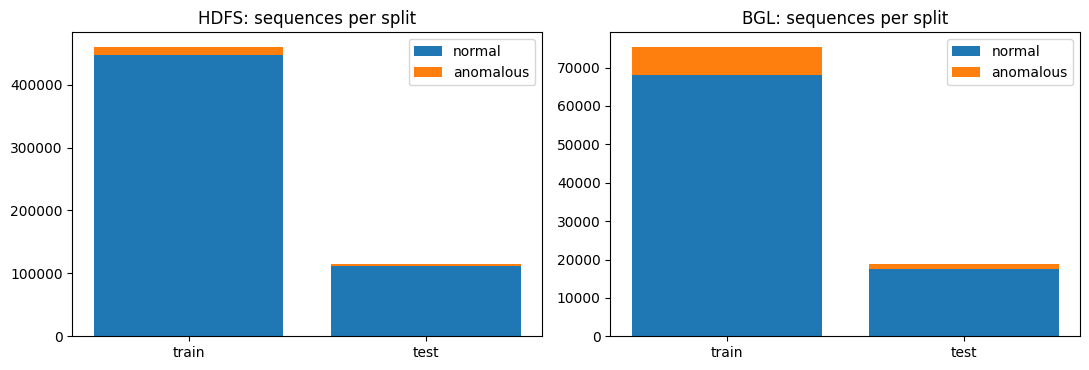

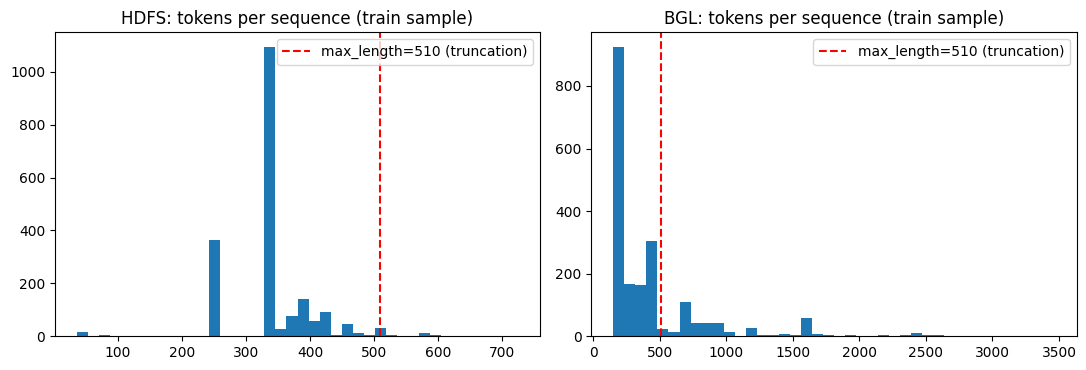

In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 5: dataset description and visualisations (Task 1) ----
def load_seq(path):
    df = pd.DataFrame(pickle.load(open(path, "rb")))
    df["y"] = df["Label"].apply(lambda x: int(max(x)) if isinstance(x, list) else int(x))
    df["n_events"] = df["EventTemplate"].apply(len)
    df["text"] = df["EventTemplate"].apply(lambda x: " ".join(x))
    return df

try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("roberta-base")
    count_tokens = lambda s: len(tok(s, add_special_tokens=True)["input_ids"])
except Exception as e:
    print("tokenizer unavailable, falling back to whitespace tokens:", e)
    count_tokens = lambda s: len(s.split())

stats, tok_lens = [], {}
for ds in DATASETS:
    for split in ("train", "test"):
        df = load_seq(f"logs_dataset/{ds}/{split}.pkl")
        if split == "train": print(ds, "- model input is the parsed EventTemplate text, e.g.:", df["EventTemplate"].iloc[0][:3])
        samp = df.sample(min(2000, len(df)), random_state=SEED)
        tl = samp["text"].apply(count_tokens)
        tok_lens[(ds, split)] = (tl.values, df["n_events"].values)
        stats.append(dict(dataset=ds, split=split, sequences=len(df), anomalous=int(df.y.sum()),
                          anomaly_pct=round(100*df.y.mean(), 2), mean_events_per_seq=round(df.n_events.mean(), 1),
                          median_tokens_sample=int(np.median(tl)), pct_over_510_tokens_sample=round(100*(tl > 510).mean(), 1)))
stats_df = pd.DataFrame(stats); stats_df.to_csv("results/dataset_stats.csv", index=False); display(stats_df)

fig, ax = plt.subplots(1, len(DATASETS), figsize=(5.5*len(DATASETS), 3.8))
ax = np.atleast_1d(ax)
for a, ds in zip(ax, DATASETS):
    s = stats_df[stats_df.dataset == ds]
    a.bar(s.split, s.sequences - s.anomalous, label="normal"); a.bar(s.split, s.anomalous, bottom=s.sequences - s.anomalous, label="anomalous")
    a.set_title(f"{ds}: sequences per split"); a.legend()
plt.tight_layout(); plt.savefig("results/fig_class_distribution.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, len(DATASETS), figsize=(5.5*len(DATASETS), 3.8)); ax = np.atleast_1d(ax)
for a, ds in zip(ax, DATASETS):
    a.hist(tok_lens[(ds, "train")][0], bins=40); a.axvline(510, color="r", ls="--", label="max_length=510 (truncation)")
    a.set_title(f"{ds}: tokens per sequence (train sample)"); a.legend()
plt.tight_layout(); plt.savefig("results/fig_sequence_lengths.png", dpi=150); plt.show()

In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 6: model summary (Task 2) ----
from transformers import AutoModelForSequenceClassification
summ = []
for name in MODELS:
    m = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
    tot = sum(p.numel() for p in m.parameters())
    open(f"results/model_summary_{name}.txt", "w").write(str(m))
    cfg = m.config
    summ.append(dict(model=name, total_params_M=round(tot/1e6, 1), layers=getattr(cfg, "num_hidden_layers", getattr(cfg, "n_layer", None)),
                     hidden=getattr(cfg, "hidden_size", getattr(cfg, "n_embd", None)), heads=getattr(cfg, "num_attention_heads", getattr(cfg, "n_head", None))))
display(pd.DataFrame(summ)); pd.DataFrame(summ).to_csv("results/model_summary.csv", index=False)

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


,model,total_params_M,layers,hidden,heads
0,roberta-base,124.6,12,768,12
1,gpt2,124.4,12,768,12


In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 7: write the metrics wrapper (does not change training) ----
RUN_MAIN = r'''# Thin wrapper around the authors' main.py. It does NOT change training. It only records extra evaluation numbers
# (anomaly-class precision/recall/F1 and the confusion matrix), because the released ReFT classification evaluation
# reports macro-averaged scores while the paper does not state which averaging it uses.
import os, sys, json, runpy
import numpy as np
from sklearn import metrics as skm
import compute_metrics as cm

_extra = {}
_orig_f1 = cm.f1_score
def f1_score(y_true, y_pred, *a, **k):
    yt = np.asarray(y_true).ravel(); yp = np.asarray(y_pred).ravel()
    tn, fp, fn, tp = skm.confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    _extra.update(dict(tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), n_test=int(len(yt)), n_anomalous=int((yt == 1).sum()),
                       f1_binary=float(skm.f1_score(yt, yp, pos_label=1, zero_division=0)),
                       precision_binary=float(skm.precision_score(yt, yp, pos_label=1, zero_division=0)),
                       recall_binary=float(skm.recall_score(yt, yp, pos_label=1, zero_division=0))))
    return _orig_f1(y_true, y_pred, *a, **k)
cm.f1_score = f1_score
try:
    runpy.run_path("main.py", run_name="__main__")
finally:
    p = os.environ.get("EXTRA_METRICS_PATH")
    if p: json.dump(_extra, open(p, "w"), indent=2)'''
open("run_main.py", "w").write(RUN_MAIN); print("run_main.py written")

run_main.py written


In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 8: training (Task 3) - closest feasible version of the authors' scripts/main_results/{roberta,gpt2}_reft.sh. Finished runs are skipped. ----
KEY = re.compile(r"(loss|f1|Training time|Test time|Traceback|Error|n_params|trainable)", re.I)
def run_one(ds, model):
    tag = f"REFT_{model}_{ds}"; out_dir = f"runs/{tag}"; os.makedirs(out_dir, exist_ok=True)
    if os.path.exists(f"{out_dir}/run_info.json"): print("already finished, skipping:", tag); return tag
    cmd = [sys.executable, "run_main.py",
           "-train_dataset", f"./logs_dataset/{ds}/train.pkl", "-eval_dataset", f"./logs_dataset/{ds}/test.pkl",
           "-model", model, "-seed", str(SEED), "-l", "all", "-r", "8",
           "-p", "f1" if model == "roberta-base" else "l1",
           "-e", str(EPOCHS[(model, ds)]), "--share_weights", "-lr", "1e-4", "-type", "LoreftIntervention",
           "-gradient_accumulation_steps", str(GRAD_ACCUM), "-batch_size", str(BATCH), "-eval_batch_size", str(BATCH),
           "-max_length", "510", "--metric_for_best_model", "f1", "--dropout", "0.1", "--weight_decay", "0.0",
           "--warmup_ratio", "0.1", "--logging_steps", "500", "--is_classification", "--do_eval", "--do_train", "--save_model",
           "-output_dir", out_dir, "-dtype", DTYPE]
    if model == "roberta-base": cmd.append("--allow_cls_grad")
    if N_TRAIN: cmd += ["--max_n_train_example", str(N_TRAIN)]
    if N_TEST:  cmd += ["--max_n_eval_example", str(N_TEST)]
    envv = dict(os.environ, EXTRA_METRICS_PATH=f"{out_dir}/extra_metrics.json", TOKENIZERS_PARALLELISM="false", WANDB_MODE="disabled")
    t0 = time.time(); tail = []
    with open(f"results/logs/{tag}.log", "w") as lf:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=envv, bufsize=1)
        for line in p.stdout:
            lf.write(line); tail.append(line); tail = tail[-40:]
            if KEY.search(line): print(line.rstrip()[:300])
        p.wait()
    if p.returncode != 0:
        print("".join(tail)); raise RuntimeError(f"{tag} failed (see results/logs/{tag}.log)")
    json.dump({"cmd": cmd, "wall_clock_s": round(time.time() - t0, 1)}, open(f"{out_dir}/run_info.json", "w"), indent=2)
    return tag

done = []
for ds in DATASETS:
    for model in MODELS:
        print(f"\n===== {model} / {ds} =====")
        done.append(run_one(ds, model))


===== roberta-base / HDFS =====
model: roberta-base, layers: all, rank: 8, position: f1, epoch: 3, max_length: 510, allow_cls_grad: True, is_classification: True, dropout: 0.1, lr: 0.0001, warmup_ratio: 0.1, weight_decay: 0.0, batch_size: 16, eval_batch_size: 16, scheduler: linear, seed: 42, is_unstable: False, inject_ratio: 0.0, 
trainable intervention params: 147,552 || trainable model params: 0
model params: 124,647,170 || trainable%: 0.1183757320763881
 67%|██████▋   | 169/252 [05:54<02:49,  2.04s/it]{'eval_f1': 0.0, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_accuracy': 0.9, 'epoch': 0.99}
{'loss': 0.2424, 'grad_norm': 4.045632362365723, 'learning_rate': 3.672566371681416e-05, 'epoch': 2.0}
100%|██████████| 252/252 [08:58<00:00,  2.12s/it]{'eval_f1': 0.46153846153846156, 'eval_precision': 1.0, 'eval_recall': 0.3, 'eval_accuracy': 0.93, 'epoch': 2.0}
{'loss': 0.1524, 'grad_norm': 4.3299946784973145, 'learning_rate': 0.0, 'epoch': 2.98}
{'eval_f1': 0.72, 'eval_precision': 0.9,

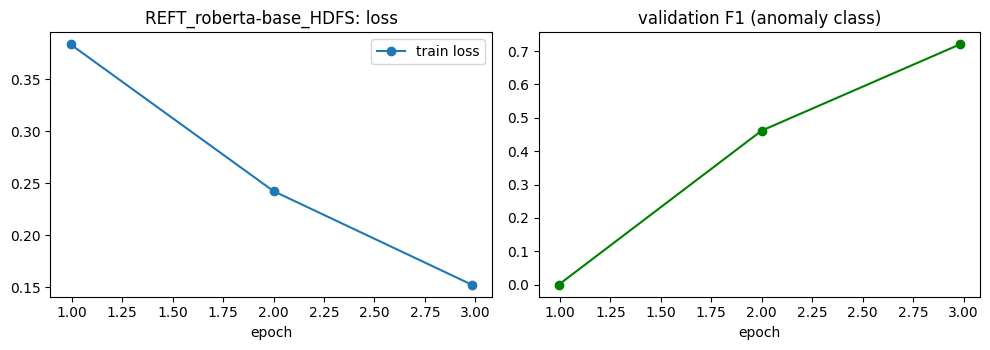

REFT_roberta-base_HDFS | train_s: 549.49386 | eval_s: 81.24086 | trainable params: 147552


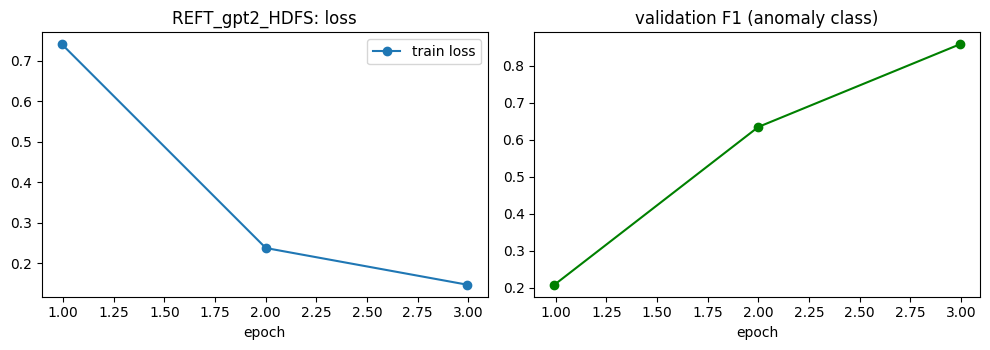

REFT_gpt2_HDFS | train_s: 1300.858722 | eval_s: 91.068523 | trainable params: 147552


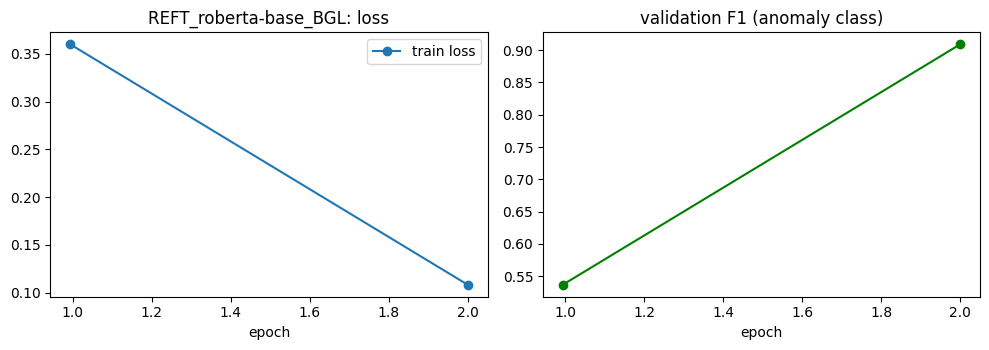

REFT_roberta-base_BGL | train_s: 1207.272015 | eval_s: 91.198631 | trainable params: 147552


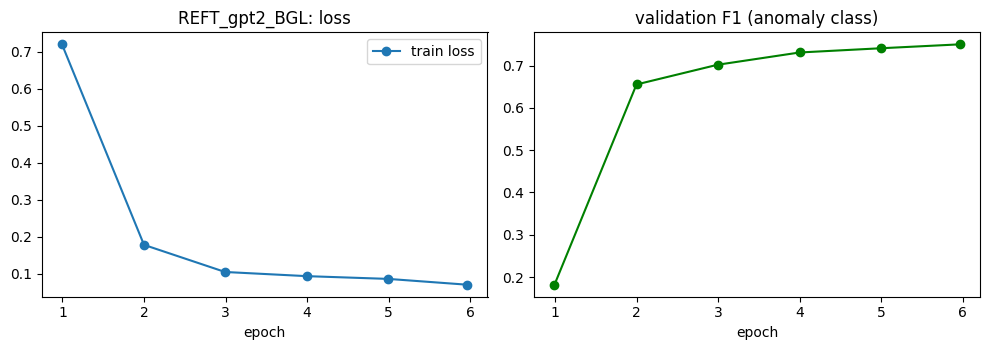

REFT_gpt2_BGL | train_s: 1402.737484 | eval_s: 98.584568 | trainable params: 147552


In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
done = [f"REFT_{m}_{d}" for d in DATASETS for m in MODELS]
# ---- CELL 9: collect results, curves, timing (Task 3/4) ----
def collect(tag):
    out = f"runs/{tag}"
    ev = json.load(open(sorted(glob.glob(f"{out}/*/eval_results.json"))[-1]))
    ex = json.load(open(f"{out}/extra_metrics.json"))
    info = json.load(open(f"{out}/run_info.json"))
    log = open(f"results/logs/{tag}.log").read()
    m = re.search(r"Training time: ([\d.]+) seconds", log); t = re.search(r"Test time: ([\d.]+) seconds", log)
    ts = sorted(glob.glob(f"{out}/**/trainer_state.json", recursive=True))
    if ts: hist = json.load(open(ts[-1]))["log_history"]
    else:
        hist = []
        for s in re.findall(r"\{[^{}]*'(?:loss|eval_loss)'[^{}]*\}", log):
            try: hist.append(ast.literal_eval(s))
            except Exception: pass
    return dict(tag=tag, eval=ev, extra=ex, hist=hist, train_s=float(m.group(1)) if m else None,
                test_s=float(t.group(1)) if t else None, wall_s=info["wall_clock_s"])

R = {tag: collect(tag) for tag in done}
for tag, r in R.items():
    h = r["hist"]
    tr = [(x["epoch"], x["loss"]) for x in h if "loss" in x and "epoch" in x]
    ev = [(x["epoch"], x["eval_loss"]) for x in h if "eval_loss" in x and "epoch" in x]
    evf = [(x["epoch"], x["eval_f1"]) for x in h if "eval_f1" in x and "epoch" in x]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    if tr: ax[0].plot(*zip(*tr), marker="o", label="train loss")
    if ev: ax[0].plot(*zip(*ev), marker="s", label="validation loss")
    ax[0].set_title(f"{tag}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    if evf: ax[1].plot(*zip(*evf), marker="o", color="g"); ax[1].set_title("validation F1 (anomaly class)"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(f"results/curves_{tag}.png", dpi=150); plt.show()
    print(tag, "| train_s:", r["train_s"], "| eval_s:", r["test_s"], "| trainable params:", r["eval"].get("n_params"))
    shutil.copy(sorted(glob.glob(f"runs/{tag}/*/args.json"))[-1], f"results/args_{tag}.json")

,Dataset,Model,Metric,Original_paper,Reproduced_macro,Diff_macro,Reproduced_anomaly_class,Diff_anomaly_class
0,HDFS,roberta-base,F1,0.9965,0.8514,-0.1451,0.7265,-0.2700
1,HDFS,roberta-base,Precision,0.9972,0.9637,-0.0335,0.9721,-0.0251
2,HDFS,roberta-base,Recall,0.9958,0.7891,-0.2067,0.5800,-0.4158
3,HDFS,gpt2,F1,0.9971,0.8666,-0.1305,0.7628,-0.2343
4,HDFS,gpt2,Precision,0.9964,0.8383,-0.1581,0.6940,-0.3024
5,HDFS,gpt2,Recall,0.9978,0.9026,-0.0952,0.8467,-0.1511
6,BGL,roberta-base,F1,0.9558,0.8911,-0.0647,0.8008,-0.1550
7,BGL,roberta-base,Precision,0.9693,0.9665,-0.0028,0.9670,-0.0023
8,BGL,roberta-base,Recall,0.9433,0.8404,-0.1029,0.6833,-0.2600
9,BGL,gpt2,F1,0.8919,0.5578,-0.3341,0.1944,-0.6975


,run,n_test,n_anomalous,tn,fp,fn,tp,train_s,eval_s,wall_s,trainable_params
0,REFT_roberta-base_HDFS,3000,300,2695,5,126,174,549.493860,81.240860,670.6,147552
1,REFT_gpt2_HDFS,3000,300,2588,112,46,254,1300.858722,91.068523,1424.0,147552
2,REFT_roberta-base_BGL,3000,300,2693,7,95,205,1207.272015,91.198631,1335.9,147552
3,REFT_gpt2_BGL,3000,300,2517,183,248,52,1402.737484,98.584568,1537.0,147552


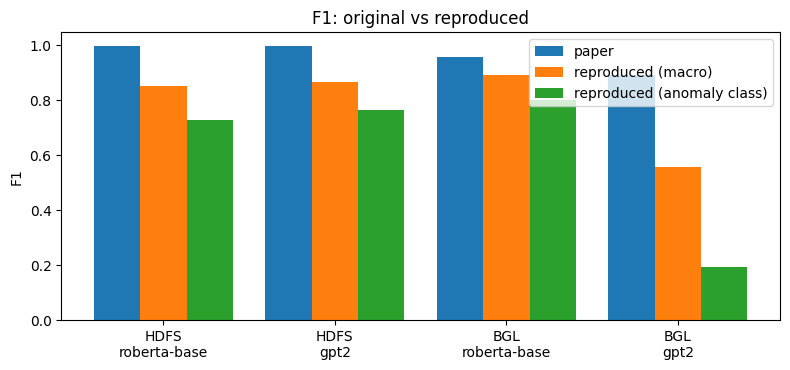

In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- CELL 10: original-vs-reproduced comparison (Task 4) ----
# Original values: Table 1 (a)(b) of Lim et al. (2025). Order: F1, Precision, Recall
PAPER = {("HDFS","roberta-base"): (0.9965, 0.9972, 0.9958), ("HDFS","gpt2"): (0.9971, 0.9964, 0.9978),
         ("BGL","roberta-base"):  (0.9558, 0.9693, 0.9433), ("BGL","gpt2"):  (0.8919, 0.8541, 0.9417)}
rows = []
for tag, r in R.items():
    _, model, ds = tag.split("_", 2)
    pf, pp, pr = PAPER[(ds, model)]
    e, x = r["eval"], r["extra"]
    for metric, orig, macro, binary in [("F1", pf, e["f1"], x["f1_binary"]), ("Precision", pp, e["precision"], x["precision_binary"]),
                                        ("Recall", pr, e["recall"], x["recall_binary"])]:
        rows.append(dict(Dataset=ds, Model=model, Metric=metric, Original_paper=orig,
                         Reproduced_macro=round(macro, 4), Diff_macro=round(macro - orig, 4),
                         Reproduced_anomaly_class=round(binary, 4), Diff_anomaly_class=round(binary - orig, 4)))
cmp_df = pd.DataFrame(rows); cmp_df.to_csv("results/comparison_table.csv", index=False); display(cmp_df)
md_lines = ["| Dataset | Model | Metric | Original paper | Reproduced (macro, repo metric) | Diff | Reproduced (anomaly class) | Diff |", "|---|---|---|---|---|---|---|---|"]
for r_ in rows:
    md_lines.append(f"| {r_['Dataset']} | {r_['Model']} | {r_['Metric']} | {r_['Original_paper']:.4f} | {r_['Reproduced_macro']:.4f} | {r_['Diff_macro']:+.4f} | {r_['Reproduced_anomaly_class']:.4f} | {r_['Diff_anomaly_class']:+.4f} |")
open("results/comparison_table.md", "w").write("\n".join(md_lines))

cm_rows = [dict(run=t, **{k: r["extra"][k] for k in ("n_test","n_anomalous","tn","fp","fn","tp")}, train_s=r["train_s"], eval_s=r["test_s"], wall_s=r["wall_s"],
                trainable_params=r["eval"].get("n_params")) for t, r in R.items()]
pd.DataFrame(cm_rows).to_csv("results/run_summary.csv", index=False); display(pd.DataFrame(cm_rows))

fig, ax = plt.subplots(figsize=(8, 3.8)); f1 = cmp_df[cmp_df.Metric == "F1"]; xs = np.arange(len(f1)); w = 0.27
ax.bar(xs - w, f1.Original_paper, w, label="paper"); ax.bar(xs, f1.Reproduced_macro, w, label="reproduced (macro)"); ax.bar(xs + w, f1.Reproduced_anomaly_class, w, label="reproduced (anomaly class)")
ax.set_xticks(xs); ax.set_xticklabels([f"{a}\n{b}" for a, b in zip(f1.Dataset, f1.Model)]); ax.set_ylabel("F1"); ax.legend(); ax.set_title("F1: original vs reproduced")
plt.tight_layout(); plt.savefig("results/fig_f1_comparison.png", dpi=150); plt.show()

In [ ]:
import os; os.chdir("/content/LogADReft"); exec(open("results/_common.py").read())
# ---- package everything for the GitHub repo / report ----
shutil.make_archive("results_package", "zip", "results")
print("Created results_package.zip  (results tables, figures, logs, configs). Model weights stay in ./runs (do not push them to GitHub).")
try:
    from google.colab import files; files.download("results_package.zip")
except Exception: pass

Created results_package.zip  (results tables, figures, logs, configs). Model weights stay in ./runs (do not push them to GitHub).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>